# Pruebas posible Paper - Análisis transversal de topologías de reservorio

**Notebook 5** de la serie de investigación del TFM de Antonio Macías Ferrera (*Estudio General de la Topología del Reservorio en Redes de Estado de Eco*, Universidad de Sevilla).

Este notebook no lanza nuevos entrenamientos: **reúne los resultados de los Notebooks 1–4** y los analiza de forma transversal para evaluar si los hallazgos del TFM tienen la solidez necesaria para un artículo. Cada sección es una prueba independiente orientada a una tabla o figura candidata del paper. Todas las tablas se exportan como **CSV** (datos) y **PNG** (figura generada con matplotlib).

## Índice

1. [Configuración del entorno](#1-configuración-del-entorno)
2. [Resultados de origen](#2-resultados-de-origen)
3. [Tabla 1 - Mejor rendimiento por topología x dataset](#3-tabla-1---mejor-rendimiento-por-topología-x-dataset)
4. [Tabla 2 - Hiperparámetros óptimos por señal sintética (S1–S10)](#4-tabla-2---hiperparámetros-óptimos-por-señal-sintética-s1s10)

## 1. Configuración del entorno

In [22]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

# ---------------------------------------------------------------------------
# Configuración global
# ---------------------------------------------------------------------------
N_FOLDS    = 10                     # pliegues de TimeSeriesSplit usados en NB1-NB4
TOPOLOGIES = ["ER", "WS", "BA"]
TOPO_NAMES = {"ER": "Erdős-Rényi", "WS": "Watts-Strogatz", "BA": "Barabási-Albert"}

OUTPUT_DIR = Path("paper_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print(f"  Pliegues CV  : {N_FOLDS}")
print(f"  Salidas en   : {OUTPUT_DIR}/")

  Pliegues CV  : 10
  Salidas en   : paper_outputs/


In [23]:
# ---------------------------------------------------------------------------
# Renderizado de tablas con matplotlib (estilo común para todas las tablas)
# ---------------------------------------------------------------------------
HEADER_COLOR    = "#b4dcbf"
STRIPE_COLOR    = "#f4f3ee"
HIGHLIGHT_COLOR = "#d4edda"
GRID_COLOR      = "#d9d9d9"
TEXT_COLOR      = "#111111"
MUTED_COLOR     = "#555555"


def fmt_num(x, decimals):
    """Número con coma decimal (formato español)."""
    return f"{x:.{decimals}f}".replace(".", ",")


def render_table(df, save_path, bold_rows=(), highlight=None, separators=(),
                 col_widths=None, fontsize=13, row_height=0.48):
    """
    Dibuja `df` como tabla con matplotlib y la guarda en PNG.

    bold_rows  : etiquetas de fila que se resaltan en negrita.
    highlight  : DataFrame booleano con la forma de `df`; True -> celda resaltada.
    separators : índices de columna tras los cuales se dibuja una línea vertical gruesa.
    """
    cell_text = [[str(df.index[i])] + [str(v) for v in df.iloc[i]] for i in range(len(df))]
    col_labels = [df.index.name or ""] + list(df.columns)
    n_rows, n_cols = len(cell_text) + 1, len(col_labels)
    col_widths = col_widths or [1.6] * n_cols

    fig, ax = plt.subplots(figsize=(sum(col_widths), n_rows * row_height))
    ax.axis("off")
    tbl = ax.table(cellText=cell_text, colLabels=col_labels, cellLoc="center",
                   colWidths=[w / sum(col_widths) for w in col_widths], bbox=[0, 0, 1, 1])
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(fontsize)

    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor(GRID_COLOR)
        cell.set_linewidth(0.6)
        if r == 0:
            cell.set_facecolor(HEADER_COLOR)
            cell.set_text_props(weight="bold", color=TEXT_COLOR)
            continue
        row_label = df.index[r - 1]
        is_bold = row_label in bold_rows
        cell.set_facecolor(STRIPE_COLOR if r % 2 == 0 else "white")
        cell.set_text_props(weight="bold" if is_bold or c == 0 else "normal",
                            color=TEXT_COLOR if is_bold or c == 0 else MUTED_COLOR)
        if highlight is not None and c > 0 and highlight.iloc[r - 1, c - 1]:
            cell.set_facecolor(HIGHLIGHT_COLOR)
            cell.set_text_props(weight="bold", color=TEXT_COLOR)

    # Separadores verticales y borde exterior
    x_edges = np.cumsum([0] + col_widths) / sum(col_widths)
    for c in separators:
        ax.plot([x_edges[c + 1]] * 2, [0, 1], color="#222222", lw=1.6,
                transform=ax.transAxes, clip_on=False)
    ax.add_patch(Rectangle((0, 0), 1, 1, fill=False, lw=1.8, edgecolor="#222222",
                           transform=ax.transAxes, clip_on=False))

    fig.savefig(save_path, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Figura guardada -> {save_path}")

## 2. Resultados de origen

Las carpetas `single_hp_outputs_*` están excluidas del repositorio, así que los valores se **transcriben de las salidas guardadas** en cada notebook (se indica la celda de origen). Para cada par (dataset, topología) se toma la **mejor configuración estructural** encontrada en la Fase B, con los hiperparámetros ESN fijados al óptimo de la Fase A del mismo dataset. Todas las métricas son media ± desviación típica sobre 10 pliegues de validación cruzada temporal.

| Dataset | Origen | Ajuste estructural |
|---|---|---|
| Seno (NB1) | NB1 §4.1–4.3 (barridos ER/BA y mapa WS) | Óptimo por topología |
| ERA5 t2m (NB2) | NB2 §6.4 (resumen entre topologías) | Óptimo por topología |
| S1–S10 (NB3) | NB3 §9 (comparación final) | Canónico de S1 (ER p=0.001, WS k=2 / p_rw=0.01, BA m=1) aplicado a todas las señales |
| NASDAQ (NB4) | NB4 §6.4 (resumen entre topologías) | Óptimo por topología |

> **Nota:** en NB3 el ajuste estructural es el canónico de S1 para las diez señales, no el óptimo por señal. Es la única fuente con media ± std para S1–S10; los estudios detallados de S1/S5/S10 (NB3 §8.1) dan el mismo ganador.

In [24]:
# ---------------------------------------------------------------------------
# Resultados de la Fase B por (dataset, topología)
# ---------------------------------------------------------------------------
# Hiperparámetros ESN (Fase A refinada) usados en la Fase B de cada dataset
ESN_PARAMS = {
    "Seno":   dict(N=400, sr=1.3, lr=0.1, ridge=5e-2, washout=10),
    "ERA5":   dict(N=500, sr=0.9, lr=0.5, ridge=1.0,  washout=5),
    "S1":     dict(N=400, sr=1.3, lr=0.1,  ridge=5e-2, washout=10),
    "S2":     dict(N=300, sr=1.1, lr=0.05, ridge=5e-2, washout=10),
    "S3":     dict(N=100, sr=0.9, lr=0.1,  ridge=5e-2, washout=10),
    "S4":     dict(N=100, sr=0.9, lr=0.1,  ridge=5e-2, washout=10),
    "S5":     dict(N=50,  sr=0.9, lr=0.1,  ridge=5e-2, washout=10),
    "S6":     dict(N=50,  sr=0.9, lr=0.1,  ridge=5e-2, washout=10),
    "S7":     dict(N=50,  sr=1.3, lr=0.1,  ridge=5e-2, washout=10),
    "S8":     dict(N=50,  sr=1.1, lr=0.1,  ridge=5e-2, washout=10),
    "S9":     dict(N=25,  sr=0.9, lr=0.1,  ridge=1e-3, washout=10),
    "S10":    dict(N=25,  sr=1.3, lr=0.2,  ridge=5e-2, washout=10),
    "NASDAQ": dict(N=100, sr=0.9, lr=0.3, ridge=1.0,  washout=100),
}

DATASET_INFO = {
    "Seno":   dict(familia="Sintético", notebook="NB1", descripcion="3 senos + ruido σ=0.05"),
    "ERA5":   dict(familia="Real",      notebook="NB2", descripcion="Temperatura horaria t2m (°C), Sevilla"),
    **{f"S{i}": dict(familia="Sintético", notebook="NB3", descripcion=d) for i, d in enumerate([
        "3 frec., σ=0.05", "5 frec., σ=0.22", "7 frec., σ=0.56", "9 frec., σ=0.85",
        "11 frec. + AM doble, σ=1.20", "12 frec., σ=1.50", "13 frec., σ=1.80",
        "14 frec., σ=2.20", "15 frec. + ruido multiplicativo, σ=2.60",
        "16 frec. + complejidad completa, σ=3.00"], start=1)},
    "NASDAQ": dict(familia="Real",      notebook="NB4", descripcion="Log-retornos diarios NASDAQ Composite"),
}

# (dataset, topología, ajuste estructural, RMSE medio, RMSE std, R² medio, celda de origen)
PHASE_B_RESULTS = [
    # --- NB1: señal seno -------------------------------------------------------
    ("Seno", "ER", "p=0.001",           0.0589,   0.0009,   0.9948,   "NB1 celda 37"),
    ("Seno", "WS", "k=2, p_rw=0.001",   0.055828, 0.003070, 0.995349, "NB1 celda 40"),
    ("Seno", "BA", "m=1",               0.0746,   0.0564,   0.9875,   "NB1 celda 42"),
    # --- NB2: ERA5 -------------------------------------------------------------
    ("ERA5", "ER", "p=0.0001",          1.1774,   0.9062,   0.9361,   "NB2 celda 59"),
    ("ERA5", "WS", "k=2, p_rw=0.001",   1.0916,   0.3873,   0.9602,   "NB2 celda 59"),
    ("ERA5", "BA", "m=1",               1.2249,   0.8218,   0.9366,   "NB2 celda 59"),
    # --- NB3: S1-S10 (topología canónica) --------------------------------------
    *[(sig, topo, setting, mean, std, np.nan, "NB3 celda 49")
      for sig, vals in {
          "S1":  [(0.05879, 0.00124), (0.05611, 0.00359), (0.05661, 0.00309)],
          "S2":  [(0.25440, 0.00420), (0.26574, 0.02990), (0.25506, 0.01792)],
          "S3":  [(0.63586, 0.01037), (0.65876, 0.10626), (0.64908, 0.08161)],
          "S4":  [(0.94256, 0.01634), (0.93010, 0.01913), (0.94462, 0.05006)],
          "S5":  [(1.30179, 0.03452), (1.28204, 0.02685), (1.28285, 0.03003)],
          "S6":  [(1.62239, 0.04765), (1.62723, 0.05879), (1.60646, 0.04561)],
          "S7":  [(1.90506, 0.04216), (1.88349, 0.03652), (1.91432, 0.07101)],
          "S8":  [(2.36990, 0.07103), (2.34002, 0.05778), (2.35966, 0.06680)],
          "S9":  [(3.55997, 0.09526), (3.54418, 0.08656), (3.54113, 0.08513)],
          "S10": [(4.43763, 0.09695), (4.43035, 0.08156), (4.42796, 0.08815)],
      }.items()
      for topo, setting, (mean, std) in zip(TOPOLOGIES, ["p=0.001", "k=2, p_rw=0.01", "m=1"], vals)],
    # --- NB4: NASDAQ -----------------------------------------------------------
    ("NASDAQ", "ER", "p=0.0001",        0.01248,  0.00401,  -0.02557, "NB4 celda 56"),
    ("NASDAQ", "WS", "k=2, p_rw=1",     0.01260,  0.00401,  -0.04891, "NB4 celda 56"),
    ("NASDAQ", "BA", "m=1",             0.01278,  0.00409,  -0.07914, "NB4 celda 56"),
]

df_long = pd.DataFrame(PHASE_B_RESULTS, columns=[
    "dataset", "topology", "structural_setting", "rmse_mean", "rmse_std", "r2_mean", "source"])
df_long["n_folds"] = N_FOLDS

DATASET_ORDER = ["Seno", "ERA5", "NASDAQ"] + [f"S{i}" for i in range(1, 11)]
df_long["dataset"] = pd.Categorical(df_long["dataset"], categories=DATASET_ORDER, ordered=True)
df_long = df_long.sort_values(["dataset", "topology"]).reset_index(drop=True)

print(f"Registros cargados: {len(df_long)} ({df_long['dataset'].nunique()} datasets x {len(TOPOLOGIES)} topologías)")
df_long.head(9)

Registros cargados: 39 (13 datasets x 3 topologías)


,dataset,topology,structural_setting,rmse_mean,rmse_std,r2_mean,source,n_folds
0,Seno,BA,m=1,0.074600,0.05640,0.987500,NB1 celda 42,10
1,Seno,ER,p=0.001,0.058900,0.00090,0.994800,NB1 celda 37,10
2,Seno,WS,"k=2, p_rw=0.001",0.055828,0.00307,0.995349,NB1 celda 40,10
3,ERA5,BA,m=1,1.224900,0.82180,0.936600,NB2 celda 59,10
4,ERA5,ER,p=0.0001,1.177400,0.90620,0.936100,NB2 celda 59,10
5,ERA5,WS,"k=2, p_rw=0.001",1.091600,0.38730,0.960200,NB2 celda 59,10
6,NASDAQ,BA,m=1,0.012780,0.00409,-0.079140,NB4 celda 56,10
7,NASDAQ,ER,p=0.0001,0.012480,0.00401,-0.025570,NB4 celda 56,10
8,NASDAQ,WS,"k=2, p_rw=1",0.012600,0.00401,-0.048910,NB4 celda 56,10


## 3. Tabla 1 - Mejor rendimiento por topología x dataset

Para cada dataset se reporta el RMSE medio ± std de la mejor configuración de cada topología (resaltada en verde la de menor RMSE medio), junto con:

- **Δ vs 2ª (%)**: mejora relativa de la ganadora frente a la segunda, $(\text{RMSE}_{2^a} - \text{RMSE}_{1^a}) / \text{RMSE}_{2^a}$.

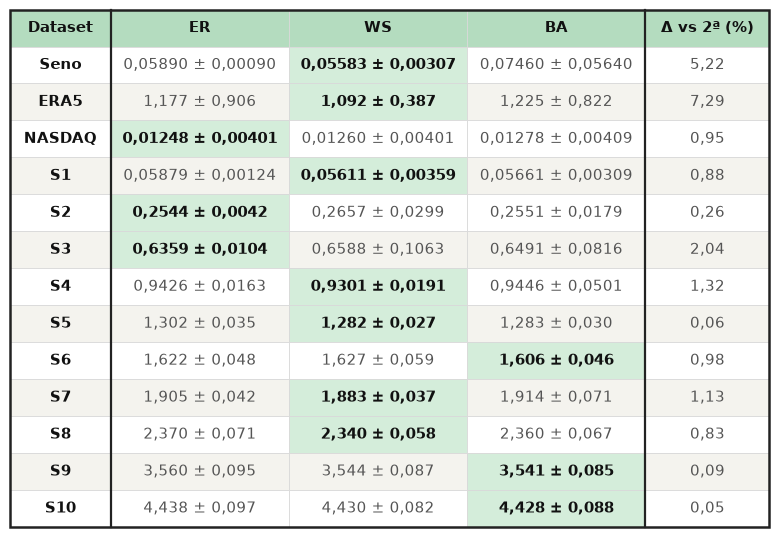

Figura guardada -> paper_outputs/table1_topology_x_dataset.png


In [25]:
# ---------------------------------------------------------------------------
# Construcción de la tabla topología x dataset
# ---------------------------------------------------------------------------
def summarize_dataset(g):
    g = g.sort_values("rmse_mean")
    best, second = g.iloc[0], g.iloc[1]
    return pd.Series({
        "winner":        best["topology"],
        "winner_rmse":   best["rmse_mean"],
        "second":        second["topology"],
        "gap_pct":       100 * (second["rmse_mean"] - best["rmse_mean"]) / second["rmse_mean"],
        "spread_pct":    100 * (g["rmse_mean"].max() - g["rmse_mean"].min()) / g["rmse_mean"].max(),
    })

summary = (df_long.groupby("dataset", observed=True)
           .apply(summarize_dataset, include_groups=False))

rmse_mean = df_long.pivot(index="dataset", columns="topology", values="rmse_mean")[TOPOLOGIES]
rmse_std  = df_long.pivot(index="dataset", columns="topology", values="rmse_std")[TOPOLOGIES]

# Tabla numérica (para CSV)
table1 = pd.concat([rmse_mean.add_suffix("_rmse_mean"), rmse_std.add_suffix("_rmse_std"), summary], axis=1)
table1.index = table1.index.astype(str)
table1.index.name = "dataset"
table1.insert(0, "familia", [DATASET_INFO[d]["familia"] for d in table1.index])
table1.insert(1, "N", [ESN_PARAMS[d]["N"] for d in table1.index])

def rmse_decimals(mean):
    # Cifras significativas adaptadas a la escala del RMSE de cada dataset
    return max(2, 3 - int(np.floor(np.log10(abs(mean)))))

# Tabla formateada (para la figura)
table1_fmt = pd.DataFrame(index=table1.index)
table1_fmt.index.name = "Dataset"
for topo in TOPOLOGIES:
    table1_fmt[topo] = [f"{fmt_num(m, rmse_decimals(m))} ± {fmt_num(s, rmse_decimals(m))}"
                        for m, s in zip(rmse_mean[topo], rmse_std[topo])]
table1_fmt["Δ vs 2ª (%)"] = [fmt_num(v, 2) for v in summary["gap_pct"]]

winner_mask = pd.DataFrame(False, index=table1_fmt.index, columns=table1_fmt.columns)
for d, w in summary["winner"].items():
    winner_mask.loc[str(d), w] = True

render_table(
    table1_fmt, OUTPUT_DIR / "table1_topology_x_dataset.png",
    highlight=winner_mask,
    separators=(0, 3),                       # tras "Dataset" y tras "BA"
    col_widths=[1.3, 2.3, 2.3, 2.3, 1.6],
    fontsize=11,
)

In [26]:
# ---------------------------------------------------------------------------
# Recuento de victorias
# ---------------------------------------------------------------------------
wins = summary["winner"].value_counts().reindex(TOPOLOGIES, fill_value=0)
wins_by_family = (summary.assign(familia=[DATASET_INFO[str(d)]["familia"] for d in summary.index])
                  .groupby("familia")["winner"].value_counts().unstack(fill_value=0)
                  .reindex(columns=TOPOLOGIES, fill_value=0))

print("Victorias por topología (menor RMSE medio):")
for topo in TOPOLOGIES:
    print(f"  {topo} ({TOPO_NAMES[topo]:16s}) : {wins[topo]:2d} / {len(summary)}")

print("\nVictorias por familia de dataset:")
print(wins_by_family.to_string())

print(f"\nMejora media de la ganadora sobre la 2ª  : {summary['gap_pct'].mean():.2f} %")
print(f"Rango medio entre mejor y peor topología : {summary['spread_pct'].mean():.2f} %")

Victorias por topología (menor RMSE medio):
  ER (Erdős-Rényi     ) :  3 / 13
  WS (Watts-Strogatz  ) :  7 / 13
  BA (Barabási-Albert ) :  3 / 13

Victorias por familia de dataset:
winner     ER  WS  BA
familia              
Real        1   1   0
Sintético   2   6   3

Mejora media de la ganadora sobre la 2ª  : 1.62 %
Rango medio entre mejor y peor topología : 4.51 %


In [27]:
# ---------------------------------------------------------------------------
# Exportación de los datos de la Tabla 1 a CSV
# ---------------------------------------------------------------------------
df_long.to_csv(OUTPUT_DIR / "table1_topology_x_dataset_long.csv", index=False)
table1.to_csv(OUTPUT_DIR / "table1_topology_x_dataset.csv")

for f in sorted(OUTPUT_DIR.glob("table1_*.csv")):
    print(f"CSV guardado -> {f}")

CSV guardado -> paper_outputs/table1_topology_x_dataset.csv
CSV guardado -> paper_outputs/table1_topology_x_dataset_long.csv


### 3.1. Lectura preliminar de la Tabla 1

- **WS es la ganadora más frecuente (7/13)**, pero su ventaja es **muy pequeña**: la mejora media de la ganadora sobre la segunda es ≈ 1.6 % y en casi todos los datasets la diferencia es menor que la desviación típica entre pliegues de cada topología. Solo en el seno de NB1 (WS vs ER, ≈ 5 %) y en ERA5 (≈ 7 %) la mejora supera el 5 %, y en ERA5 la dispersión entre pliegues es muy grande. Con el diseño actual (una semilla, 10 pliegues) no se puede afirmar que una topología sea mejor que otra.
- **Seno (NB1) y S1 (NB3) son la misma señal base**: en una tabla final conviene conservar solo una de las dos filas para no contar dos veces el mismo caso.
- **Las tres topologías óptimas convergen a reservorios extremadamente dispersos** (ER p ≤ 0.001, WS k=2, BA m=1). Esto sugiere que la ventaja depende más de la **densidad/conectividad efectiva** que de la familia topológica, lo cual es en sí un resultado publicable si se controla la densidad.
- **NASDAQ tiene R² < 0** para las tres topologías: el modelo no supera a predecir la media. Para el paper hace falta comparar contra *baselines* triviales (persistencia, media, AR(p)), o reformular la tarea (volatilidad, dirección).
- **En S1–S10** el ajuste estructural es el canónico de S1; las diferencias entre topologías se diluyen a medida que aumenta el ruido (σ ≥ 1.2), donde el error está dominado por el componente estocástico irreducible.

## 4. Tabla 2 - Hiperparámetros óptimos por señal sintética (S1–S10)

Mejor configuración de la ESN para cada una de las diez señales de dificultad creciente del Notebook 3, con su RMSE medio de validación cruzada.

**De dónde salen los datos:** NB3 §3.2 *Optimización de hiperparámetros de la ESN por señal* (celda 14, salida `best_params_per_signal.csv`).

- **Procedimiento:** búsqueda en rejilla completa independiente para cada señal, con 10 pliegues de `TimeSeriesSplit` y entrada de $L=10$ retardos estandarizados.
- **Rejilla (135 configuraciones):** $N \in \{25, 50, 100, 300, 400\}$, $\varrho \in \{0.9, 1.1, 1.3\}$, $\alpha \in \{0.05, 0.1, 0.2\}$, ridge $\in \{10^{-3}, 10^{-2}, 5\cdot10^{-2}\}$, washout $= 10$.
- **Reservorio:** `reservoirpy.nodes.Reservoir` por defecto (conectividad aleatoria dispersa tipo ER con `rc_connectivity=0.1`); es decir, es la **Fase A**, previa al estudio de topología.
- **RMSE CV:** media del RMSE sobre los 10 pliegues de la mejor configuración. NB3 solo guarda la media en esta búsqueda, por lo que no hay desviación típica.
- **S1** no usa el resultado de la rejilla de NB3 sino la **referencia refinada del Notebook 1** (N=400, ϱ=1.3, α=0.1, ridge=0.05), porque su RMSE (0.05382) es menor que el de la rejilla local (0.05391). La salida de NB3 imprime los parámetros de NB1 junto al RMSE de la rejilla local; aquí se usa el RMSE de NB1 para que fila y parámetros sean coherentes.
- **Filas en negrita:** S1, S5 y S10, las tres señales con estudio de topología detallado en NB3 §4–6 (dificultad baja, media y alta).

Notación: $\varrho$ = radio espectral (`sr`), $\alpha$ = tasa de fuga (`lr`).

CSV guardado -> paper_outputs/table2_best_hyperparams_per_signal.csv


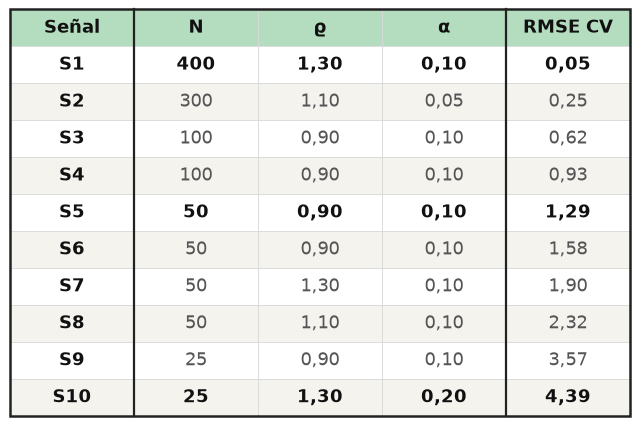

Figura guardada -> paper_outputs/table2_best_hyperparams_per_signal.png


In [28]:
# ---------------------------------------------------------------------------
# Hiperparámetros óptimos por señal (NB3 celda 14)
# ---------------------------------------------------------------------------
# (señal, N, sr, lr, ridge, washout, RMSE CV, fuente)
NB3_PHASE_A = [
    ("S1",  400, 1.3, 0.10, 5e-2, 10, 0.05382, "Referencia refinada NB1 (celda 30)"),
    ("S2",  300, 1.1, 0.05, 5e-2, 10, 0.24742, "Búsqueda por señal NB3 (celda 14)"),
    ("S3",  100, 0.9, 0.10, 5e-2, 10, 0.62133, "Búsqueda por señal NB3 (celda 14)"),
    ("S4",  100, 0.9, 0.10, 5e-2, 10, 0.92503, "Búsqueda por señal NB3 (celda 14)"),
    ("S5",   50, 0.9, 0.10, 5e-2, 10, 1.29359, "Búsqueda por señal NB3 (celda 14)"),
    ("S6",   50, 0.9, 0.10, 5e-2, 10, 1.57797, "Búsqueda por señal NB3 (celda 14)"),
    ("S7",   50, 1.3, 0.10, 5e-2, 10, 1.89837, "Búsqueda por señal NB3 (celda 14)"),
    ("S8",   50, 1.1, 0.10, 5e-2, 10, 2.31697, "Búsqueda por señal NB3 (celda 14)"),
    ("S9",   25, 0.9, 0.10, 1e-3, 10, 3.57047, "Búsqueda por señal NB3 (celda 14)"),
    ("S10",  25, 1.3, 0.20, 5e-2, 10, 4.38984, "Búsqueda por señal NB3 (celda 14)"),
]

table2 = pd.DataFrame(NB3_PHASE_A, columns=["signal", "N", "sr", "lr", "ridge", "washout", "rmse_cv", "source"])
table2.insert(1, "descripcion", [DATASET_INFO[s]["descripcion"] for s in table2["signal"]])
table2 = table2.set_index("signal")
table2.to_csv(OUTPUT_DIR / "table2_best_hyperparams_per_signal.csv")
print(f"CSV guardado -> {OUTPUT_DIR / 'table2_best_hyperparams_per_signal.csv'}")

table2_fmt = pd.DataFrame({
    "N":       table2["N"].astype(str),
    "ϱ":       [fmt_num(v, 2) for v in table2["sr"]],
    "α":       [fmt_num(v, 2) for v in table2["lr"]],
    "RMSE CV": [fmt_num(v, 2) for v in table2["rmse_cv"]],
}, index=table2.index)
table2_fmt.index.name = "Señal"

render_table(
    table2_fmt, OUTPUT_DIR / "table2_best_hyperparams_per_signal.png",
    bold_rows=("S1", "S5", "S10"),
    separators=(0, 3),                       # tras "Señal" y antes de "RMSE CV"
    col_widths=[1.6, 1.6, 1.6, 1.6, 1.6],
)

### 4.1. Lectura de la Tabla 2

- **El tamaño óptimo del reservorio disminuye con la dificultad** (N = 400 → 25): cuanto más ruidosa es la señal, más pequeño es el reservorio que generaliza mejor. Con ruido alto, un reservorio grande sobreajusta el componente estocástico.
- **α = 0.1 es casi universal** (8/10 señales); solo S2 (0.05) y S10 (0.2) se desvían.
- **ϱ no muestra un patrón monótono**: alterna entre 0.9, 1.1 y 1.3, lo que indica que la superficie de error es plana en ϱ dentro de la rejilla.
- **El RMSE crece casi linealmente con σ del ruido**, lo que confirma que en las señales difíciles el error está dominado por el ruido irreducible y deja poco margen para diferencias entre topologías (ver Tabla 1).

### Implicaciones para el paper (próximas pruebas en este notebook)

1. Repetir la Fase B con **varias semillas** (≥ 10) y un test pareado por pliegue (Wilcoxon / Friedman + Nemenyi entre topologías).
2. Comparación **a densidad igualada** (mismo número de aristas en ER, WS y BA) para separar el efecto de la estructura del de la conectividad.
3. Normalizar el error (NRMSE) para poder agregar resultados entre datasets y producir un ranking medio (diagrama de diferencias críticas).
4. Añadir *baselines* (persistencia, ridge lineal sobre los lags, ESN sin recurrencia) para medir cuánto aporta el reservorio.